In [ ]:
# CELL 1: install dependencies (with numpy fix)
!pip install -U "numpy<2.0" ultralytics opencv-python matplotlib --no-cache-dir

import os, shutil, zipfile, glob, random, pathlib
import matplotlib.pyplot as plt
import cv2
from ultralytics import YOLO
from google.colab import files

random.seed(42)

print("✅ Libraries installed.")


INFO: pip is looking at multiple versions of opencv-python to determine which version is compatible with other requirements. This could take a while.
✅ Libraries installed.


In [ ]:
# CELL 2: upload 2 zip files
print("👉 Upload 2 files:")
print("1) Crop_and_weed_detection-cleaned.zip (project)")
print("2) Your DATASET zip (images + YOLO .txt labels)")

uploaded = files.upload()
assert len(uploaded) == 2, f"Please upload exactly 2 files (got {len(uploaded)})."

zip_names = list(uploaded.keys())
proj_zip = None
data_zip = None

for z in zip_names:
    zl = z.lower()
    if "crop_and_weed_detection" in zl or "cleaned" in zl or "project" in zl:
        proj_zip = z
    else:
        data_zip = z

# Fallback if names are confusing
if proj_zip is None or data_zip is None:
    proj_zip, data_zip = zip_names[0], zip_names[1]

print(f"✅ Project zip: {proj_zip}")
print(f"✅ Dataset zip: {data_zip}")


👉 Upload 2 files:
1) Crop_and_weed_detection-cleaned.zip (project)
2) Your DATASET zip (images + YOLO .txt labels)


Saving archive (16).zip to archive (16).zip
Saving Crop_and_weed_detection-cleaned.zip to Crop_and_weed_detection-cleaned.zip
✅ Project zip: Crop_and_weed_detection-cleaned.zip
✅ Dataset zip: archive (16).zip


In [ ]:
# CELL 3: paths & unzip

ROOT = "/content"
PROJ_DIR = f"{ROOT}/project"
RAW_DATA_DIR = f"{ROOT}/dataset_raw"
YOLO_DATA_DIR = f"{ROOT}/dataset_yolo"
RUNS_DIR = f"{ROOT}/yolo_runs"

for p in [PROJ_DIR, RAW_DATA_DIR, YOLO_DATA_DIR, RUNS_DIR]:
    os.makedirs(p, exist_ok=True)

def unzip_to(src_zip, dst_dir):
    with zipfile.ZipFile(src_zip, 'r') as zf:
        zf.extractall(dst_dir)

print("📦 Unzipping project…")
unzip_to(proj_zip, PROJ_DIR)
print("📦 Unzipping dataset…")
unzip_to(data_zip, RAW_DATA_DIR)
print("✅ Unzipped both.")


📦 Unzipping project…
📦 Unzipping dataset…
✅ Unzipped both.


In [ ]:
# CELL 4: build list of (image, label) pairs For each image, it finds the corresponding label file (.txt) by checking possible label folders.

IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")

for p in [
    f"{YOLO_DATA_DIR}/images/train",
    f"{YOLO_DATA_DIR}/images/val",
    f"{YOLO_DATA_DIR}/labels/train",
    f"{YOLO_DATA_DIR}/labels/val",
]:
    os.makedirs(p, exist_ok=True)

def find_all_images(base):
    out = []
    for ext in IMG_EXT:
        out.extend(glob.glob(os.path.join(base, "**", f"*{ext}"), recursive=True))
    return out

def label_for_image(img_path):
    base = os.path.splitext(os.path.basename(img_path))[0] + ".txt"

    candidates = [
        os.path.join(os.path.dirname(img_path), base),
        os.path.join(os.path.dirname(img_path), "labels", base),
    ]

    d = pathlib.Path(img_path).parent
    for parent in [d] + list(d.parents):
        cand = os.path.join(str(parent), "labels", base)
        candidates.append(cand)

    for c in candidates:
        if os.path.exists(c):
            return c
    return None

all_imgs = find_all_images(RAW_DATA_DIR)
paired = []

for img in all_imgs:
    lab = label_for_image(img)
    if lab:
        paired.append((img, lab))

print(f"🖼 Total images found: {len(all_imgs)}")
print(f"✅ Paired (image + label): {len(paired)}")

assert len(paired) > 0, "❌ No (image,label) pairs found. Check that your labels are .txt with same name as images."


🖼 Total images found: 1300
✅ Paired (image + label): 1300


In [ ]:
# CELL 5: 80/20 split and copy to YOLO dirs

random.shuffle(paired)
split = max(1, int(0.8 * len(paired)))
train_pairs = paired[:split]
val_pairs   = paired[split:]

def copy_pair(pair, split_name):
    img, lab = pair
    img_dst = os.path.join(YOLO_DATA_DIR, "images", split_name, os.path.basename(img))
    lab_dst = os.path.join(YOLO_DATA_DIR, "labels", split_name, os.path.basename(lab))
    shutil.copy2(img, img_dst)
    shutil.copy2(lab, lab_dst)

for pr in train_pairs:
    copy_pair(pr, "train")
for pr in val_pairs:
    copy_pair(pr, "val")

print("✅ Copied into YOLO folders:")
print("Train imgs:", len(os.listdir(f"{YOLO_DATA_DIR}/images/train")))
print("Val imgs:", len(os.listdir(f"{YOLO_DATA_DIR}/images/val")))
print("Train labels:", len(os.listdir(f"{YOLO_DATA_DIR}/labels/train")))
print("Val labels:", len(os.listdir(f"{YOLO_DATA_DIR}/labels/val")))


✅ Copied into YOLO folders:
Train imgs: 1040
Val imgs: 260
Train labels: 1040
Val labels: 260


In [ ]:
# CELL 6: create data.yaml
#This code creates a data configuration file (data.yaml) required by YOLO for training.
yaml_path = f"{ROOT}/crop_weed.yaml"
yaml_text = """\
path: /content/dataset_yolo
train: images/train
val: images/val

nc: 2
names: ['crop', 'weed']
"""
with open(yaml_path, "w") as f:
    f.write(yaml_text)

print("✅ Created YAML at:", yaml_path)
print("------ content ------")
print(open(yaml_path).read())
print("---------------------")


✅ Created YAML at: /content/crop_weed.yaml
------ content ------
path: /content/dataset_yolo
train: images/train
val: images/val

nc: 2
names: ['crop', 'weed']

---------------------


🚀 Starting YOLOv8n training...
Ultralytics 8.3.245 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/crop_weed.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=crop-weed-v8n, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=15, pe

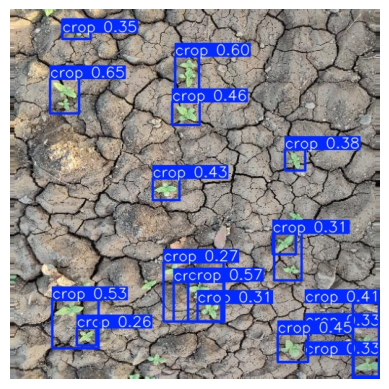

In [ ]:
# CELL 7: train YOLOv8n The code loads the YOLOv8 nano (yolov8n.pt) model and starts training it on the crop–weed dataset.

#Training is done for 30 epochs with image size 640×640, batch size 16, and early stopping using patience.

#All training results and model weights are saved inside the specified runs directory.

#After training, the code automatically finds the best trained model (best.pt).

print("🚀 Starting YOLOv8n training...")
model = YOLO("yolov8n.pt")

train_results = model.train(
    data=yaml_path,
    epochs=30,
    imgsz=640,
    batch=16,
    patience=15,
    project=RUNS_DIR,
    name="crop-weed-v8n",
)
print("✅ Training finished.")

# Find best.pt
ckpts = sorted(glob.glob(f"{RUNS_DIR}/crop-weed-v8n*/weights/best.pt"))
assert ckpts, "❌ No best.pt found. Check training logs."
best = ckpts[-1]
print(f"✅ Best weights: {best}")

# Quick inference on a few val images
val_imgs = sorted(glob.glob(f"{YOLO_DATA_DIR}/images/val/*"))[:4]
if not val_imgs:
    val_imgs = sorted(glob.glob(f"{YOLO_DATA_DIR}/images/train/*"))[:4]

print("🔍 Running predictions on:", val_imgs)
pred = model.predict(val_imgs, save=True, project="/content/yolo_infer", name="val_samples")

saved_preds = sorted(glob.glob("/content/yolo_infer/val_samples/*"))
print(f"✅ Saved {len(saved_preds)} result images to /content/yolo_infer/val_samples")

if saved_preds:
    img = cv2.imread(saved_preds[0])
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.show()


In [ ]:
import glob

paths = glob.glob("/content/yolo_runs/**/weights/best.pt", recursive=True)
print("Found:", paths)


Found: ['/content/yolo_runs/crop-weed-v8n/weights/best.pt']


In [ ]:
from ultralytics import YOLO
import cv2, numpy as np
import matplotlib.pyplot as plt

model_path = "/content/yolo_runs/crop-weed-v8n/weights/best.pt"
model = YOLO(model_path)
print("Model Loaded Successfully:", model_path)


Model Loaded Successfully: /content/yolo_runs/crop-weed-v8n/weights/best.pt


In [ ]:
!pip install -q "numpy<2.0" ultralytics gradio opencv-python pillow matplotlib --no-cache-dir

from ultralytics import YOLO
import numpy as np
import cv2
import gradio as gr

# 👉 CHANGE THIS IF YOUR PATH IS DIFFERENT
MODEL_PATH = "/content/yolo_runs/crop-weed-v8n/weights/best.pt"

model = YOLO(MODEL_PATH)
print("Model loaded ✅")
print("Class names:", model.names)


Model loaded ✅
Class names: {0: 'crop', 1: 'weed'}


In [ ]:
!pip install -q gradio opencv-python-headless pillow


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.5/16.5 MB 132.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
numba 0.60.0 requires numpy<2.1,>=1.22, but you have numpy 2.2.6 which is incompatible.
tensorflow 2.19.0 requires numpy<2.2.0,>=1.26.0, but you have numpy 2.2.6 which is incompatible.


In [ ]:
!pip install -q gradio pillow opencv-python-headless numpy

In [ ]:
!pip install -q ultralytics onnxruntime

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.4/17.4 MB 127.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.0/46.0 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 86.8/86.8 kB 8.4 MB/s eta 0:00:00


In [ ]:
# If not installed already, install ultralytics (for YOLOv8)
!pip install -q ultralytics gradio

import os, io, sys, traceback
from pathlib import Path
from PIL import Image, ImageDraw, ImageFont
import numpy as np
import cv2
import gradio as gr

# ---------- USER CONFIG ----------
# MODEL_TYPE options: None, "yolov8", "yolov5", "onnx", "tf", "tflite"
MODEL_TYPE = "yolov8"   # We are using YOLOv8
MODEL_PATH = "/content/yolo_runs/crop-weed-v8n/weights/best.pt"  # <-- your best.pt path

CONF_THRESH = 0.25           # confidence threshold to display boxes
IOU_THRESH = 0.45            # (used by some libs if needed)
# ---------------------------------


# ---------- Helper: draw boxes (NOW GREEN FOR CROP, RED FOR WEED) ----------
def draw_boxes_pil(pil_img, detections):
    # detections: list of (label, x1,y1,x2,y2,score)
    img = pil_img.convert("RGB")
    draw = ImageDraw.Draw(img)
    try:
        font = ImageFont.truetype("/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf", 14)
    except:
        font = None

    for det in detections:
        if len(det) == 6:
            label, x1, y1, x2, y2, score = det
        else:
            # fallback: unpack first 6 items
            label, x1, y1, x2, y2, score = det[0], det[1], det[2], det[3], det[4], det[5]

        # clamp coordinates
        x1, y1, x2, y2 = map(int, [max(0, x1), max(0, y1), max(0, x2), max(0, y2)])

        # Decide colors based on label type
        t = label_to_type(label)
        if t == "crop":
            outline_color = "#22c55e"   # bright green
            text_bg = "#16a34a"
        elif t == "weed":
            outline_color = "#ef4444"   # red
            text_bg = "#b91c1c"
        else:
            outline_color = "#eab308"   # yellow for unknown
            text_bg = "#facc15"

        draw.rectangle([x1, y1, x2, y2], outline=outline_color, width=3)
        txt = f"{label} {score:.2f}"
        text_size = draw.textsize(txt, font=font) if font else (len(txt) * 6, 12)
        # background rectangle for text
        draw.rectangle(
            [x1, y1 - text_size[1] - 6, x1 + text_size[0] + 6, y1],
            fill=text_bg
        )
        draw.text((x1 + 3, y1 - text_size[1] - 3), txt, fill="white", font=font)
    return img


# ---------- Fallback green-area detector (robust) ----------
def fallback_demo_boxes(image_path):
    # Uses HSV mask + contours to return boxes labeled 'weed' or 'crop'
    img = cv2.imread(image_path)
    if img is None:
        return []
    h, w = img.shape[:2]
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    lower, upper = np.array([25, 40, 40]), np.array([90, 255, 255])
    mask = cv2.inRange(hsv, lower, upper)
    # Clean up
    kernel = np.ones((5, 5), np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel, iterations=1)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel, iterations=1)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    boxes = []
    for c in contours:
        x, y, ww, hh = cv2.boundingRect(c)
        area = ww * hh
        if area < 500:   # ignore very small
            continue
        # decide label by area or aspect
        label = "weed" if area < (w * h) * 0.02 else "crop"
        boxes.append((label, x, y, x + ww, y + hh, 0.5))
    return boxes


# ---------- Model loaders & standardization ----------
# Each loader should set `standard_predict(image_path)` to return list[(label,x1,y1,x2,y2,score), ...]
standard_predict = None

# Helper: to ensure images are read for shape
def read_image_size(path):
    pil = Image.open(path)
    return pil.size  # (width, height)


# 1) YOLOv8 (ultralytics) loader
def try_load_yolov8(path):
    try:
        from ultralytics import YOLO
    except Exception as e:
        raise RuntimeError("Please install ultralytics (pip install ultralytics) to use yolov8 models") from e
    model = YOLO(path)

    def predict_yolov8(image_path):
        res = model.predict(source=image_path, conf=CONF_THRESH, imgsz=640, verbose=False)
        if len(res) == 0:
            return []
        r = res[0]
        boxes = []
        for box in r.boxes:
            try:
                xyxy = box.xyxy.tolist()[0]
            except:
                continue
            x1, y1, x2, y2 = xyxy
            conf = float(box.conf) if hasattr(box, "conf") else float(
                box.confidence) if hasattr(box, "confidence") else 0.0
            cls = int(box.cls) if hasattr(box, "cls") else 0
            name = model.names[cls] if hasattr(model, "names") and cls in model.names else str(cls)
            boxes.append((name, x1, y1, x2, y2, conf))
        return boxes

    return predict_yolov8


# 2) YOLOv5 loader (torch.hub)
def try_load_yolov5(path):
    try:
        import torch
    except Exception as e:
        raise RuntimeError("Please install torch to use yolov5: pip install torch torchvision") from e
    model = torch.hub.load('ultralytics/yolov5', 'custom', path=path, force_reload=False)
    model.conf = CONF_THRESH

    def predict_yolov5(image_path):
        results = model(image_path)
        df = results.pandas().xyxy[0]
        boxes = []
        for _, row in df.iterrows():
            name = row['name'] if 'name' in row else str(int(row['class']))
            x1, y1, x2, y2, conf = float(row['xmin']), float(row['ymin']), float(row['xmax']), float(row['ymax']), float(
                row['confidence'])
            boxes.append((name, x1, y1, x2, y2, conf))
        return boxes

    return predict_yolov5


# 3) ONNX loader
def try_load_onnx(path):
    try:
        import onnxruntime as ort
    except Exception as e:
        raise RuntimeError("Please install onnxruntime to use onnx models") from e
    sess = ort.InferenceSession(path, providers=['CPUExecutionProvider'])
    input_name = sess.get_inputs()[0].name

    def predict_onnx(image_path):
        img = cv2.imread(image_path)
        h0, w0 = img.shape[:2]
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img_res = cv2.resize(img_rgb, (640, 640))
        img_in = img_res.astype(np.float32) / 255.0
        img_in = np.transpose(img_in, (2, 0, 1))[None, ...]
        outputs = sess.run(None, {input_name: img_in})
        out = outputs[0]
        boxes = []
        if out is None:
            return boxes
        out = np.array(out)
        if out.ndim == 2 and out.shape[1] >= 6:
            for row in out:
                x_c, y_c, w, h, conf, cls = row[:6]
                if conf < CONF_THRESH:
                    continue
                x1 = (x_c - w / 2) * w0
                y1 = (y_c - h / 2) * h0
                x2 = (x_c + w / 2) * w0
                y2 = (y_c + h / 2) * h0
                boxes.append((str(int(cls)), x1, y1, x2, y2, float(conf)))
        return boxes

    return predict_onnx


# 4) TensorFlow / Keras .h5 loader (simple wrapper)
def try_load_tf(path):
    try:
        import tensorflow as tf
    except Exception as e:
        raise RuntimeError("Please install tensorflow to use tf models") from e
    model = tf.keras.models.load_model(path)

    def predict_tf(image_path):
        img = Image.open(image_path).convert("RGB")
        w0, h0 = img.size
        img_res = img.resize((640, 640))
        arr = np.array(img_res) / 255.0
        inp = np.expand_dims(arr, 0).astype(np.float32)
        out = model.predict(inp)
        out = np.array(out)
        boxes = []
        if out.ndim == 2 and out.shape[1] >= 6:
            for row in out:
                cls = int(row[0])
                x1, y1, x2, y2, conf = row[1:6]
                boxes.append((str(cls), x1 * w0, y1 * h0, x2 * w0, y2 * h0, float(conf)))
        return boxes

    return predict_tf


# 5) TFLite loader
def try_load_tflite(path):
    try:
        import tensorflow as tf
    except Exception as e:
        raise RuntimeError("Please install tensorflow to use tflite") from e
    interpreter = tf.lite.Interpreter(model_path=path)
    interpreter.allocate_tensors()
    input_details = interpreter.get_input_details()
    output_details = interpreter.get_output_details()

    def predict_tflite(image_path):
        img = Image.open(image_path).convert("RGB")
        w0, h0 = img.size
        img_res = img.resize((640, 640))
        arr = np.expand_dims(np.array(img_res, dtype=np.float32) / 255.0, 0)
        interpreter.set_tensor(input_details[0]['index'], arr)
        interpreter.invoke()
        outputs = [interpreter.get_tensor(od['index']) for od in output_details]
        boxes = []
        if len(outputs) >= 3:
            b, scores, classes = outputs[0], outputs[1], outputs[2]
            for i in range(b.shape[1] if b.ndim > 1 else b.shape[0]):
                conf = float(scores[0, i])
                if conf < CONF_THRESH:
                    continue
                y1, x1, y2, x2 = b[0, i]
                boxes.append((str(int(classes[0, i])), x1 * w0, y1 * h0, x2 * w0, y2 * h0, conf))
        return boxes

    return predict_tflite


# ---------- Attempt to load according to MODEL_TYPE ----------
if MODEL_TYPE is not None and MODEL_PATH is not None:
    try:
        mp = str(MODEL_PATH)
        if MODEL_TYPE.lower() == "yolov8":
            standard_predict = try_load_yolov8(mp)
            print("[MODEL] YOLOv8 loaded")
        elif MODEL_TYPE.lower() == "yolov5":
            standard_predict = try_load_yolov5(mp)
            print("[MODEL] YOLOv5 loaded")
        elif MODEL_TYPE.lower() == "onnx":
            standard_predict = try_load_onnx(mp)
            print("[MODEL] ONNX model loaded")
        elif MODEL_TYPE.lower() == "tf":
            standard_predict = try_load_tf(mp)
            print("[MODEL] TensorFlow/Keras model loaded")
        elif MODEL_TYPE.lower() == "tflite":
            standard_predict = try_load_tflite(mp)
            print("[MODEL] TFLite model loaded")
        else:
            print("[MODEL] Unknown MODEL_TYPE. Falling back to demo.")
            standard_predict = None
    except Exception as e:
        print(f"[MODEL LOAD ERROR] {e}\n{traceback.format_exc()}")
        standard_predict = None
else:
    standard_predict = None


# Utility: decide if a label should be counted as crop/weed
def label_to_type(label):
    lab = str(label).lower()
    # common weed keywords
    if "weed" in lab or "grass" in lab or "dandelion" in lab:
        return "weed"
    # common crop/vegetation keywords
    if any(k in lab for k in ["crop", "veg", "veget", "plant", "leaf", "corn", "wheat", "rice", "soy"]):
        return "crop"
    # fallback: if label numeric or unknown, return unknown
    return "unknown"


# Wrapper used by the Gradio UI
def pipeline_run(pil_img):
    # Save input image temporarily
    input_path = "/content/input_image_for_inference.png"
    pil_img.save(input_path)
    try:
        if standard_predict is None:
            boxes = fallback_demo_boxes(input_path)
        else:
            preds = standard_predict(input_path)
            # preds expected in various forms; normalize
            boxes = []
            if preds is None:
                preds = []
            for p in preds:
                if isinstance(p, (list, tuple)):
                    if len(p) == 6:
                        boxes.append((str(p[0]), float(p[1]), float(p[2]), float(p[3]), float(p[4]), float(p[5])))
                    elif len(p) == 5:
                        boxes.append((str(p[0]), float(p[1]), float(p[2]), float(p[3]), float(p[4]), 0.5))
                    elif len(p) == 4:
                        boxes.append(("weed", float(p[0]), float(p[1]), float(p[2]), float(p[3]), 0.5))
                    else:
                        try:
                            boxes.append(
                                (str(p[0]), float(p[1]), float(p[2]), float(p[3]), float(p[4]), float(p[5])))
                        except:
                            continue
                else:
                    continue

        # Count crops and weeds using heuristic
        crop_count = 0
        weed_count = 0
        unknown_count = 0
        for b in boxes:
            label = b[0]
            t = label_to_type(label)
            if t == "crop":
                crop_count += 1
            elif t == "weed":
                weed_count += 1
            else:
                unknown_count += 1

        # Build status text
        status = f"Crops: {crop_count} | Weeds: {weed_count}"
        status += f" | Unknown: {unknown_count} | Total boxes: {len(boxes)}"

        out_img = draw_boxes_pil(pil_img, boxes)
        return out_img, status

    except Exception as e:
        # any error -> fallback to robust demo and show error
        try:
            boxes = fallback_demo_boxes(input_path)
            out_img = draw_boxes_pil(pil_img, boxes)
            crop_count = sum(1 for b in boxes if b[0].lower().startswith("crop"))
            weed_count = sum(1 for b in boxes if b[0].lower().startswith("weed"))
            status = f"Crops: {crop_count} | Weeds: {weed_count} (Fallback applied, error: {e})"
            return out_img, status
        except Exception as e2:
            return pil_img, f"Critical error: {e}. Also fallback failed: {e2}"


# ---------- Fancy CSS for more colorful UI ----------
custom_css = """
body {
    background: radial-gradient(circle at top left, #166534 0, #022c22 40%, #020617 100%);
}

/* Main app container */
.gradio-container {
    max-width: 1100px;
    margin: 20px auto !important;
    padding: 20px !important;
    border-radius: 24px;
    background: rgba(15, 23, 42, 0.92);
    box-shadow: 0 24px 60px rgba(0, 0, 0, 0.65);
    color: #ecfdf5;
    font-family: system-ui, -apple-system, BlinkMacSystemFont, "Segoe UI", sans-serif;
}

/* Title */
.gradio-container h1 {
    text-align: center;
    font-weight: 800;
    font-size: 2.2rem;
    letter-spacing: 0.06em;
    color: #bbf7d0;
    text-shadow: 0 4px 18px rgba(22, 163, 74, 0.8);
}

/* Description area */
.hero-wrap {
    margin-top: 4px;
    margin-bottom: 18px;
    text-align: center;
}

.hero-sub {
    font-size: 0.98rem;
    color: #e5e7eb;
    max-width: 750px;
    margin: 0 auto;
    line-height: 1.6;
}

/* Badges row */
.badge-row {
    display: flex;
    justify-content: center;
    gap: 14px;
    margin-top: 14px;
    flex-wrap: wrap;
}

.badge {
    display: inline-flex;
    align-items: center;
    gap: 6px;
    padding: 6px 14px;
    border-radius: 999px;
    font-size: 0.82rem;
    font-weight: 600;
    letter-spacing: 0.03em;
    text-transform: uppercase;
    box-shadow: 0 7px 18px rgba(15, 23, 42, 0.65);
}

.badge i {
    font-size: 1rem;
}

/* Individual badge colors */
.badge.crop {
    background: linear-gradient(135deg, #15803d, #22c55e);
    color: #ecfdf5;
}

.badge.weed {
    background: linear-gradient(135deg, #dc2626, #f97316);
    color: #fef2f2;
}

.badge.ai {
    background: linear-gradient(135deg, #0ea5e9, #22c55e);
    color: #e0f2fe;
}

.badge.acc {
    background: linear-gradient(135deg, #7c3aed, #f97316);
    color: #fef9c3;
}

/* Input/output cards */
.svelte-1ipelgc,
.svelte-1ipelgc > div,
.wrap.svelte-1ipelgc {
    background: linear-gradient(145deg, rgba(15,118,110,0.18), rgba(17,24,39,0.98)) !important;
    border-radius: 22px !important;
    border: 1px solid rgba(52,211,153,0.25) !important;
    backdrop-filter: blur(10px);
}

/* Buttons */
button {
    border-radius: 999px !important;
    font-weight: 700 !important;
    letter-spacing: 0.05em !important;
    text-transform: uppercase !important;
    padding: 10px 20px !important;
    box-shadow: 0 14px 32px rgba(22,163,74,0.55) !important;
}

button.primary {
    background: linear-gradient(135deg, #16a34a, #22c55e) !important;
    border: none !important;
    color: #ecfdf5 !important;
}

button.primary:hover {
    transform: translateY(-1px);
    box-shadow: 0 20px 40px rgba(21, 128, 61, 0.8) !important;
}

/* Image component */
img {
    border-radius: 18px !important;
}

/* Counts textbox */
textarea, .wrap textarea {
    background: rgba(15, 23, 42, 0.96) !important;
    border-radius: 18px !important;
    border: 1px solid rgba(52,211,153,0.4) !important;
    color: #bbf7d0 !important;
    font-weight: 600 !important;
}

/* Small footer text */
.footer-note {
    margin-top: 10px;
    font-size: 0.75rem;
    color: #9ca3af;
}

/* Make camera/placeholder SVG icons light so they are visible */
.gradio-container svg {
    color: #e5e7eb !important;
    fill: #e5e7eb !important;
}
"""

# ---------- Gradio UI ----------
iface = gr.Interface(
    fn=pipeline_run,
    inputs=gr.Image(type="pil", label="📤 Upload Field Image"),
    outputs=[
        gr.Image(label="📍 Detections (Crops & Weeds)"),
        gr.Textbox(label="📊 Detection Summary")
    ],
    title="🌿 AgriVision – YOLOv8 Weed & Crop Detection",
    description="""
<div class="hero-wrap">
  <div class="hero-sub">
    Upload an image of your field and let our <b>YOLOv8-powered</b> AI instantly highlight
    <span style="color:#4ade80;font-weight:600;">crops</span> and
    <span style="color:#fb7185;font-weight:600;">weeds</span> with smart, color-coded boxes.
  </div>
  <div class="badge-row">
    <div class="badge crop"><i>🌱</i> Crops → Green Boxes</div>
    <div class="badge weed"><i>🌿</i> Weeds → Red Boxes</div>
    <div class="badge ai"><i>⚡</i> Real-Time YOLOv8 AI</div>
    <div class="badge acc"><i>🎯</i> High Precision</div>
  </div>
  <div class="footer-note">
    Supported formats: JPG, PNG, WEBP · Best results with clear, top-view field images.
  </div>
</div>
""",
    css=custom_css
)

iface.launch(inline=True)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 29.2 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
[MODEL LOAD ERROR] [Errno 2] No such file or directory: '/content/yolo_runs/crop-weed-v8n/weights/best.pt'
Traceback (most recent call last):
  File "/tmp/ipykernel_6294/666884516.py", line 257, in <cell line: 0>
    standard_predict = try_load_yolov8(mp)
                       ^^^^^^^^^^^^^^^^^^^
  File "/tmp/ipykernel_6294/666884516.py", line 108, in try_load_yolov8
    model = YOLO(path)
            ^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/ultralytics/models/yolo/model.py", line 76, in __init__
    super().__init__(model=model, task=task, verbose=verbose)
  File "/usr/local/lib/python